# Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

In [118]:
import pandas as pd
statdata = pd.read_csv('./data/statdata.csv')
print(statdata.shape)
statdata.head()

(750983, 11)


,cpu_time,feature_rank,ranking_method,replica_no,name,description,recall,precision,fpr,f1,auc
0,3.855204,4.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.333333,0.222222,0.500000,0.888889
1,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,0.500000
2,3.855204,5.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.250000,0.333333,0.400000,0.833333
3,3.855204,3.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.500000,0.111111,0.666667,0.944444
4,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,0.500000


In [45]:
print(statdata.shape)
subset = statdata[statdata['name'] != 'Missing Values']
subset = subset[subset['name'] != 'Continuous Endpoints (Threshold)']
subset = subset[subset['name'] != 'Continuous Endpoints (GAMETES)']
subset = subset[subset['ranking_method'] != 'Stability Selection']
# subset = subset[subset['description'].str.contains('h=1')]
print(subset.shape)

(750983, 11)
(745593, 11)


In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

F1 scores

In [119]:
# max_f1 = subset.groupby(['description', 'ranking_method', 'replica_no']).agg({'f1': 'max'})
# mean_f1 = max_f1.reset_index().groupby(['description', 'ranking_method']).agg({'f1': 'mean'})
# maxmean = mean_f1.reset_index()

# rectangular = pd.pivot_table(maxmean,\
#     values='f1',\
#     index=['description'],\
#     columns=['ranking_method'])
# f, ax = plt.subplots(figsize=(7, 25))
# plt.yticks(rotation=0)
# plt.xticks(rotation=0)
# ax = sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
# plt.title('f1 scores per unique dataset')

PR and ROC Curve

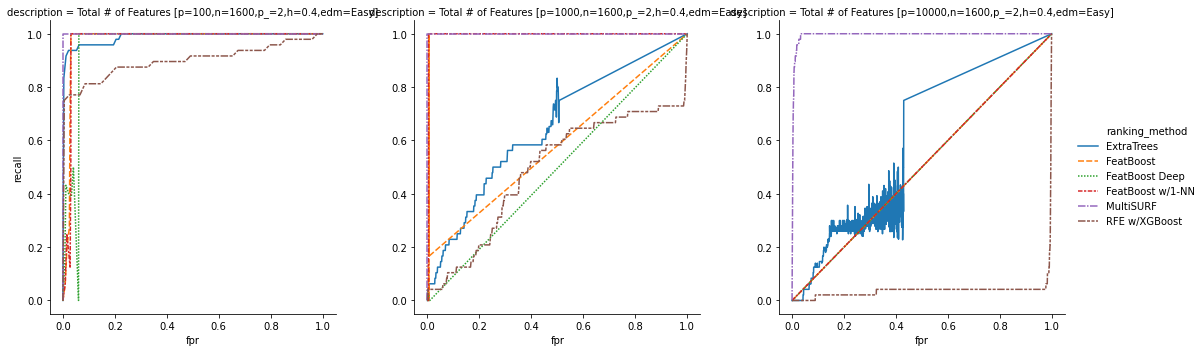

In [81]:
small_subset = subset
small_subset = subset[
        (subset['name'] == 'Total # of Features')
    ]
res = small_subset.groupby(['description', 'ranking_method', 'feature_rank'])\
                  .agg({'recall': 'mean', 'fpr': 'mean'})\
                  .reset_index()

extrarows = []
for key, data in res.groupby(['description', 'ranking_method']):
    descr, rm = key

    dat = pd.DataFrame(data={
        'description': descr,
        'ranking_method': rm,
        'recall': [0, 1],
        'fpr': [0, 1]
    })
    extrarows.append(dat)
res = pd.concat([res, pd.concat(extrarows)])

g = sns.relplot(x='fpr', y='recall', hue='ranking_method', style='ranking_method',
                col='description', kind='line', estimator=None,
                data=res, col_wrap=3, facet_kws={'sharex': False, 'sharey': False})

Text(0.5, 1.0, 'AUC score per dataset')

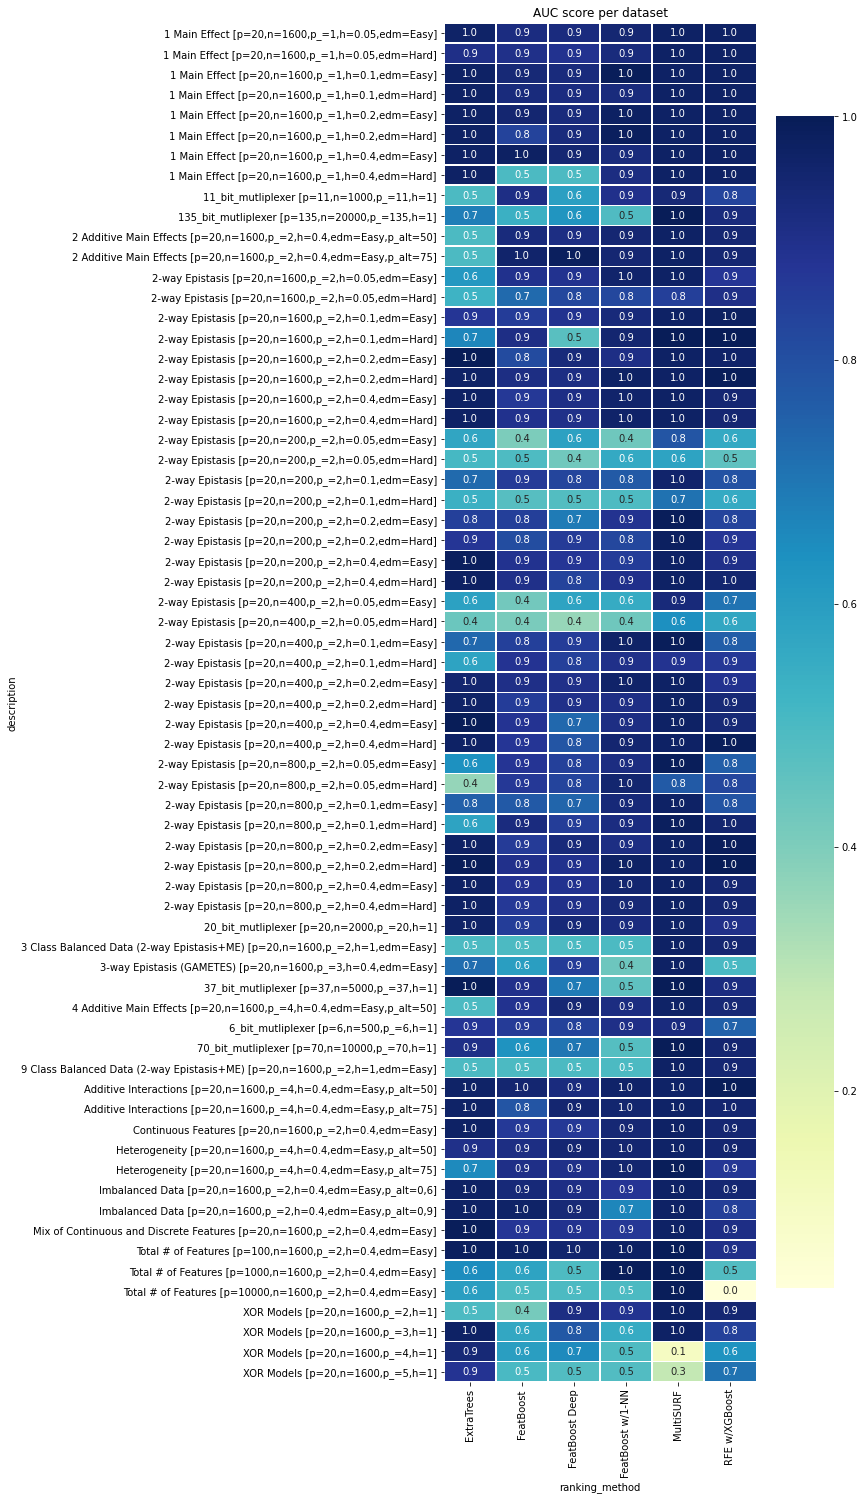

In [117]:
import numpy as np
res2 = subset.groupby(['description', 'ranking_method', 'feature_rank'])\
             .agg({'recall': 'mean', 'fpr': 'mean'})\
             .reset_index()

aucs_df = pd.DataFrame()
chunks = []
for key, data in res2.groupby(['description', 'ranking_method']):
    descr, rm = key

    data = data.append(pd.DataFrame(data={ 'fpr': [0, 1], 'recall': [0, 1] }))
    sorted_data = data.sort_values('fpr')

    real_auc = np.trapz(sorted_data.recall.values, sorted_data.fpr.values)
    chunks.append(pd.DataFrame(data={
        'description': descr,
        'ranking_method': rm,
        'auc': [real_auc]
    }))
aucs_df = pd.concat(chunks)
del chunks

# Plot AUC's in table
rectangular = pd.pivot_table(aucs_df,\
    values='auc',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(rectangular,\
    annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('AUC score per dataset')

Text(0.5, 1.0, 'recall per ranking method for all datasets')

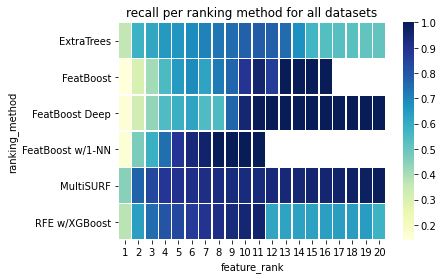

In [120]:
subset2 = subset[subset['feature_rank'] <= 20]

from matplotlib.ticker import FuncFormatter
rectangular = pd.pivot_table(subset2,\
    values='recall',\
    index=['ranking_method'],\
    columns=['feature_rank'])
g = sns.heatmap(rectangular,\
    linewidths=.5, cmap="YlGnBu")
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
plt.title('recall per ranking method for all datasets')

Construct a sensible subset for plotting

In [121]:
# subset = statdata.copy()
# for dataset, data in statdata.groupby('description'):
#     all_replicas = data.groupby('replica_no')
#     if len(all_replicas.count()) != 24: # only 'finished' datasets
#         subset = subset[subset['description'] != dataset]
#     else: # add newline in plot title
#         descr = dataset.replace(' [p=', '\n[p=')
#         descr = descr.replace(',h=', ',\nh=')
#         subset = subset.replace({ 'description': dataset }, descr)
#         # short_descr = '[p=' + dataset.split(' [p=')[1]
#         # entries = subset[subset['description'] == dataset]
#         # subset.loc[entries.index, 'short_descr'] = short_descr
# subset = subset[subset['feature_rank'] <= 20]
# subset = subset[subset['ranking_method'] != 'Stability Selection']
# subset.shape

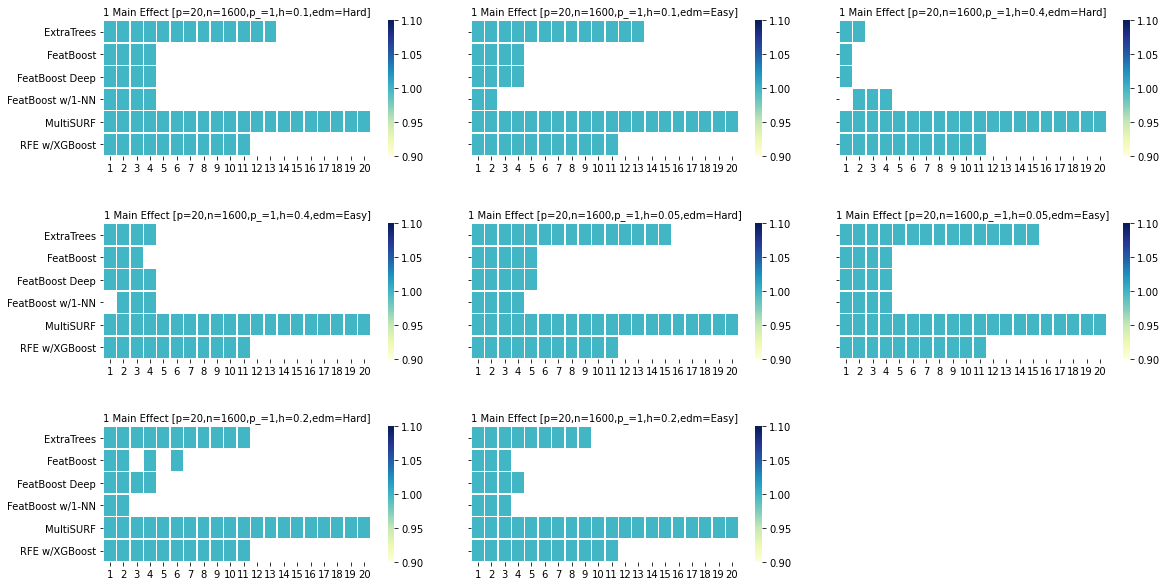

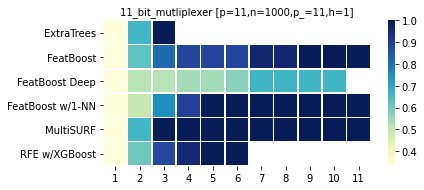

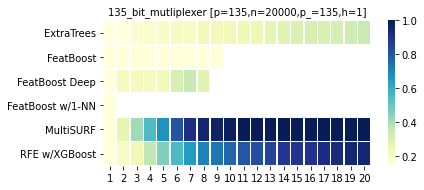

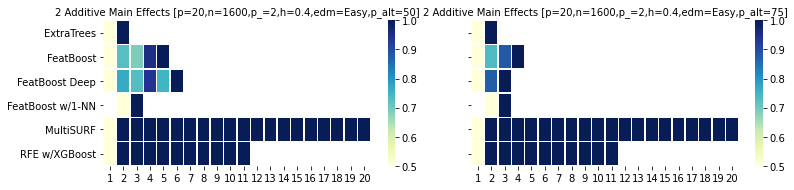

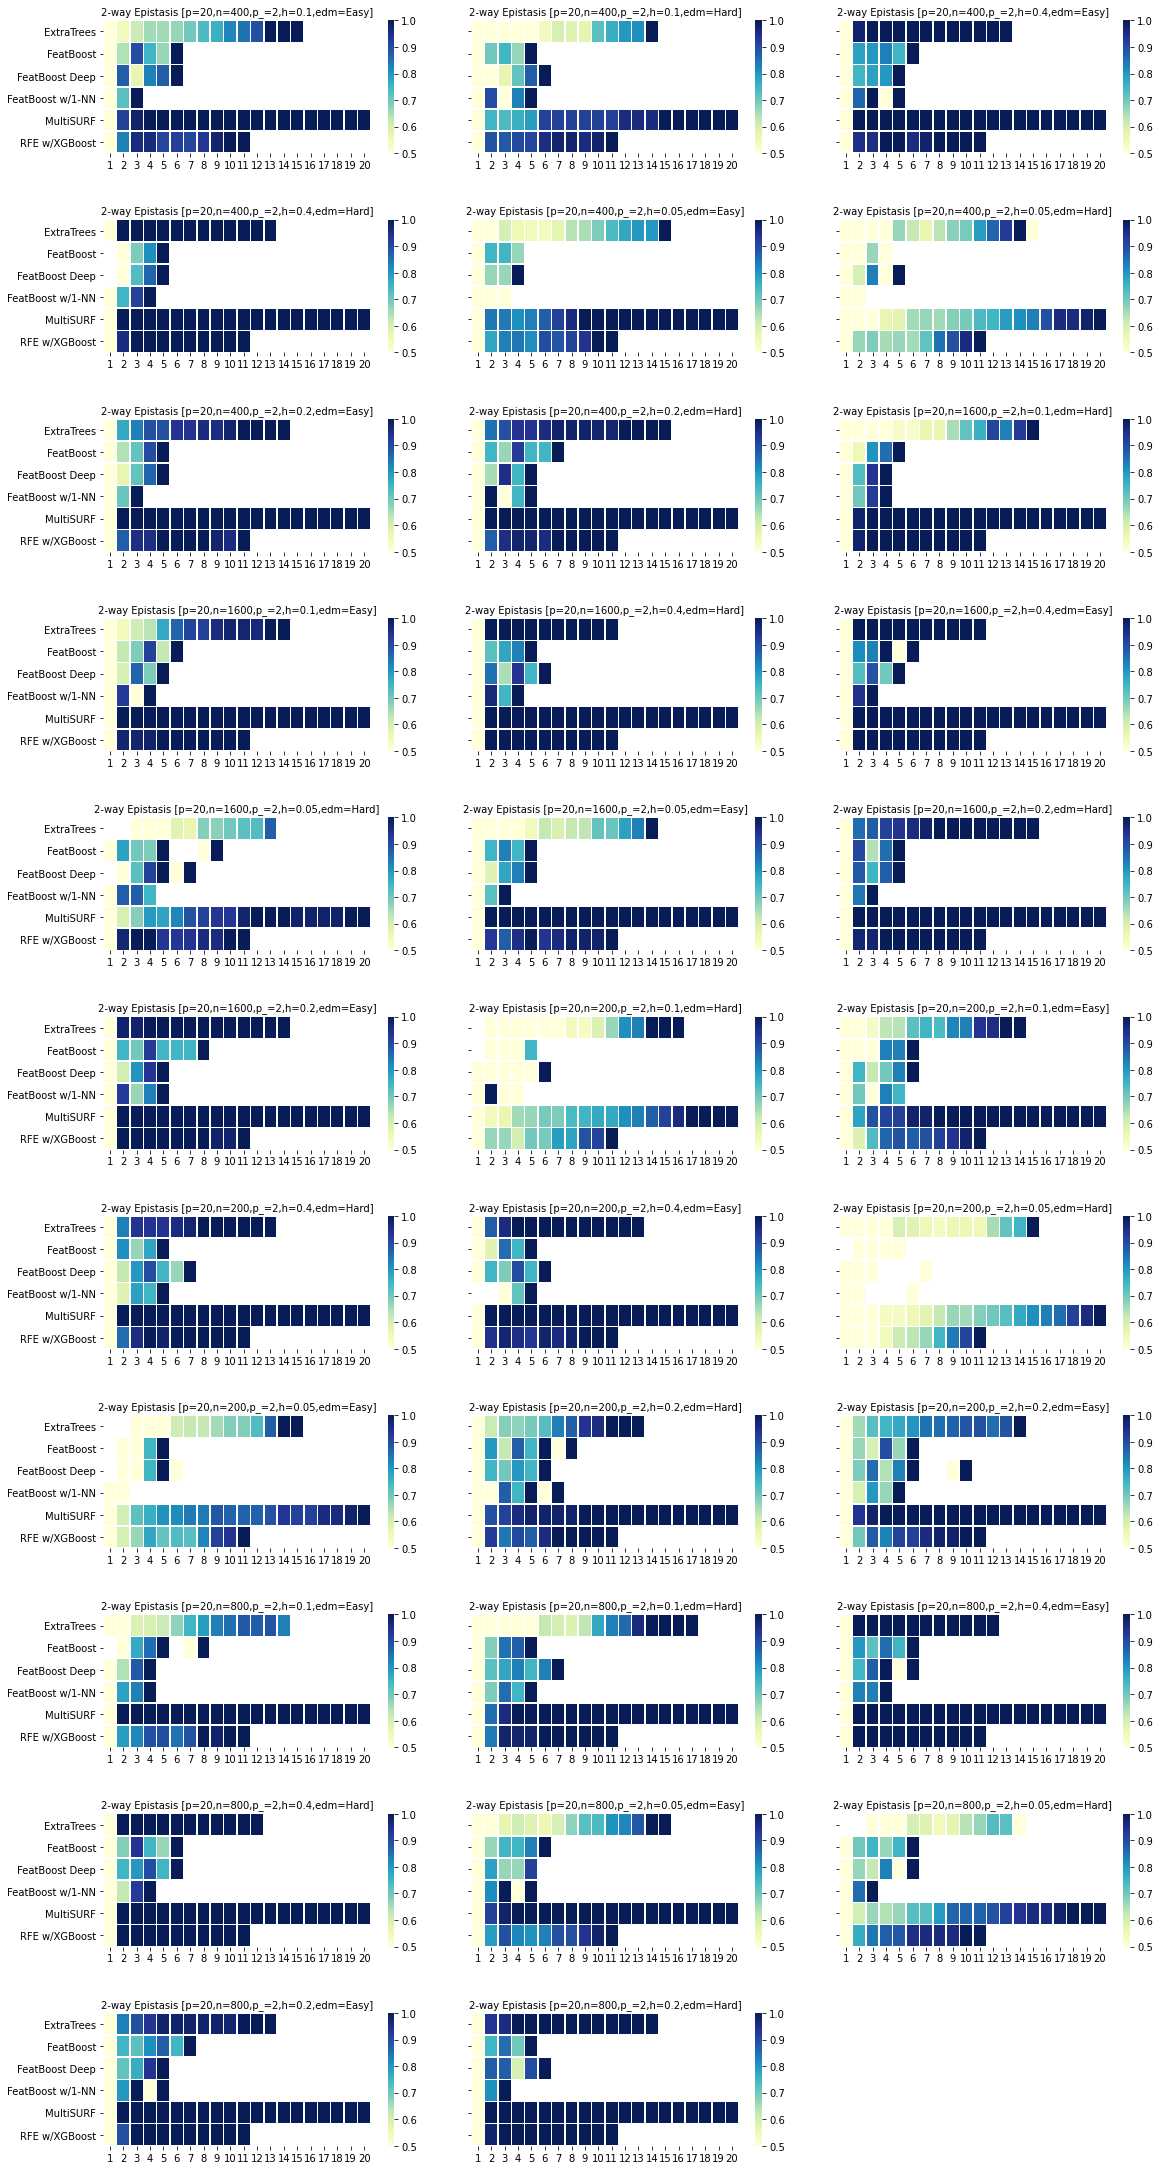

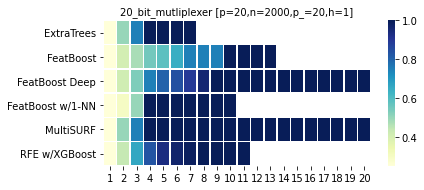

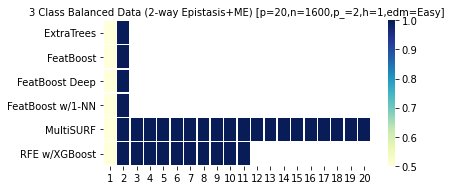

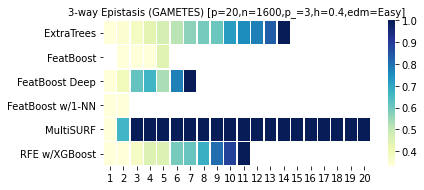

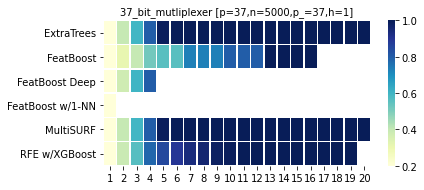

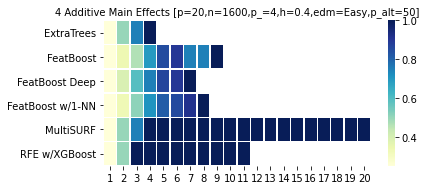

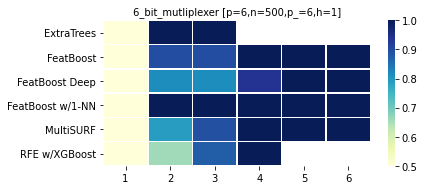

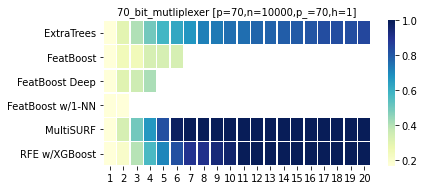

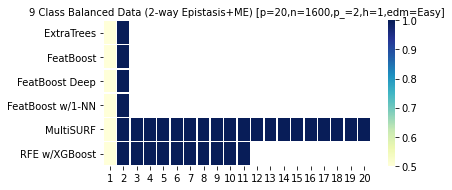

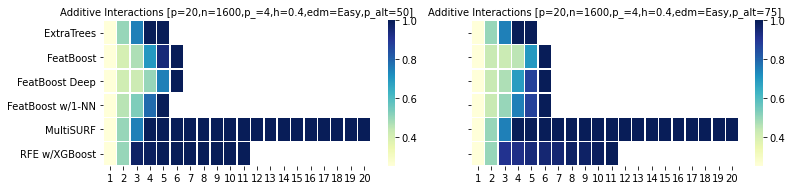

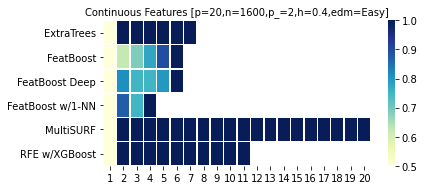

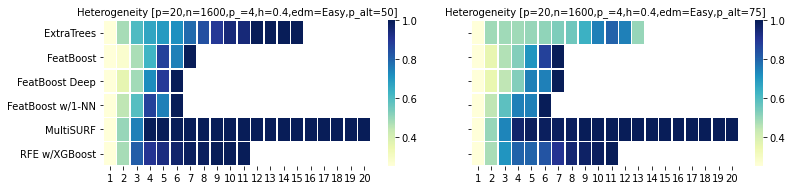

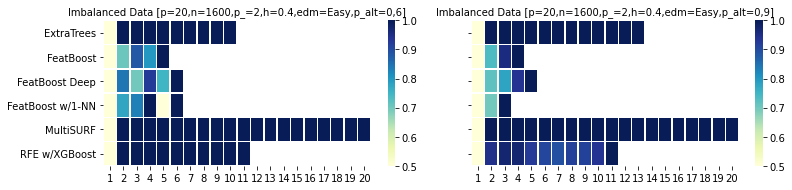

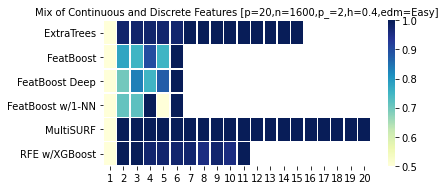

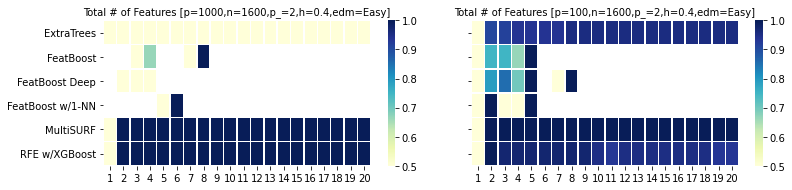

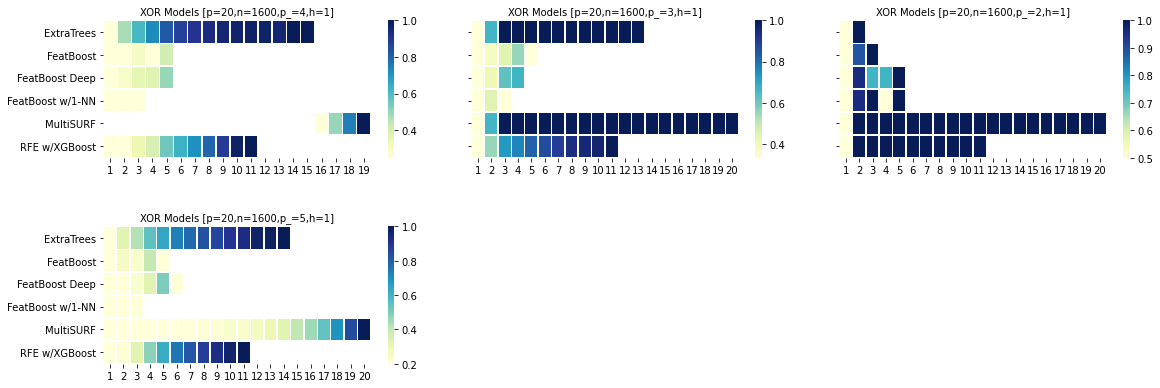

In [8]:
def draw_heatmap(*args, **kwargs):
    data = kwargs.pop('data')
    rect = pd.pivot_table(data, values='recall',\
                        index=['ranking_method'],\
                        columns=['feature_rank'])
    sns.heatmap(rect, linewidths=.5, cmap="YlGnBu")
    plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
    plt.yticks(rotation=0)
    plt.xticks(rotation=0)

def pltrecall(data, title):
    fg = sns.FacetGrid(data, col='description', sharex=False, col_wrap=3, size=2.75, aspect=2)
    fg.map_dataframe(draw_heatmap).set_titles("{col_name}")
    fg.fig.subplots_adjust(wspace=0.1, hspace=0.5)
    # plt.subplots_adjust(top=0.875)
    # fg.fig.suptitle(title)
    # fg.fig.tight_layout()

for name, data in subset2.groupby('name'):
    pltrecall(data, name)

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

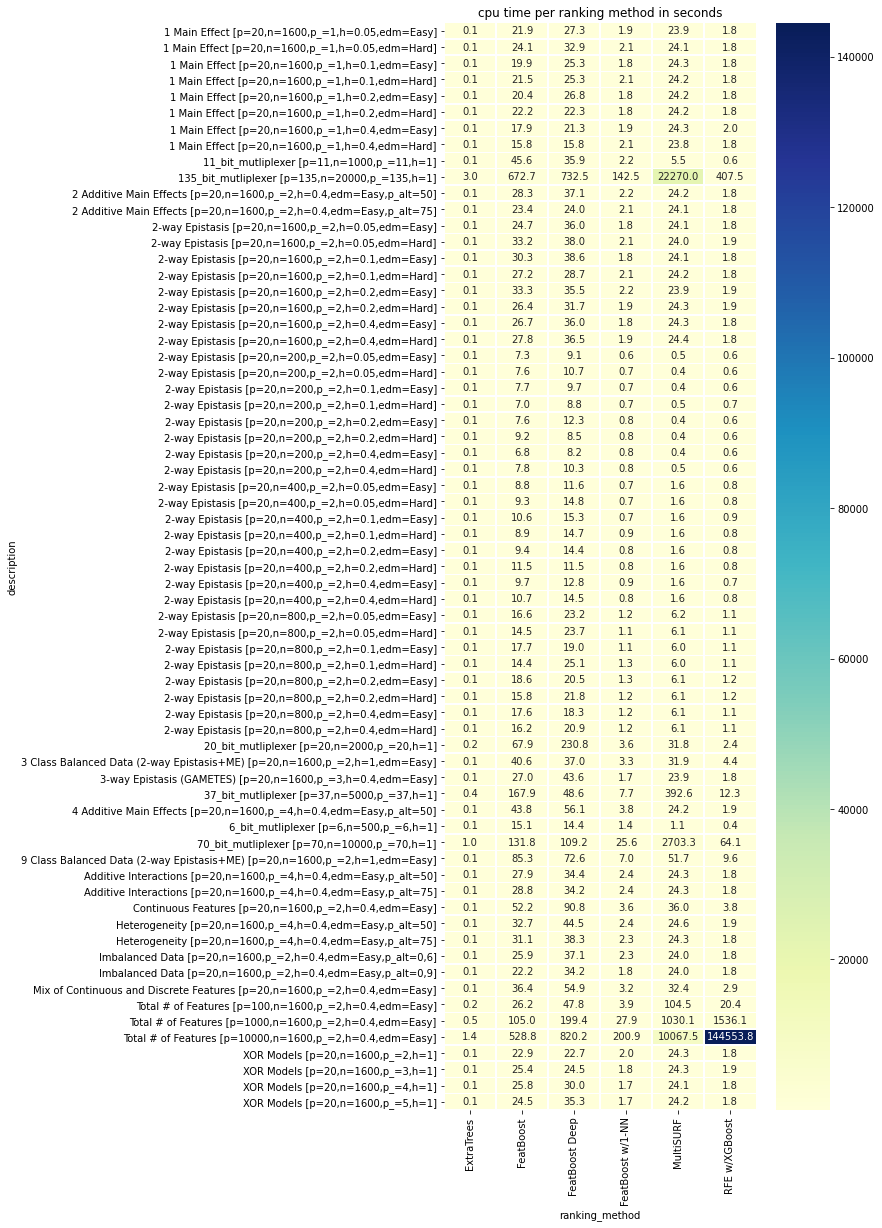

In [122]:
import seaborn as sns
import matplotlib.pyplot as plt
pivot = pd.pivot_table(subset,\
    values='cpu_time', index=['description'], columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 20))
ax = sns.heatmap(pivot, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('cpu time per ranking method in seconds')